In [1]:
!pip install -q pyagrum networkx matplotlib

# Exercițiul 4 – Rețele Markov

Avem cinci variabile binare:

- A1, A2, A3, A4, A5
- Fiecare variabilă poate avea valoarea 0 sau 1.

Muchiile rețelei sunt:

- A1 — A2
- A1 — A3
- A2 — A4
- A2 — A5
- A3 — A4
- A4 — A5

## a) Graful și clicile

O rețea Markov este reprezentată printr-un graf neorientat.

O clică este un grup de noduri în care fiecare nod este conectat
direct cu toate celelalte noduri din grup.

O clică maximală este o clică în care nu mai putem adăuga un alt
nod fără să pierdem proprietatea de clică.

Clicile maximale ale grafului sunt:

- {A1, A2}
- {A1, A3}
- {A3, A4}
- {A2, A4, A5}

Grupul {A2, A4, A5} este o clică deoarece există muchiile
A2—A4, A2—A5 și A4—A5.

## b) Probabilitatea comună și configurația MAP

Fiecare clică maximală are un potențial:

ϕ_C(a_C) = exp(β · Σ a_i · a_j)

Suma se face peste toate perechile distincte de variabile din clică.

Probabilitatea comună a unei configurații este:

P(a1, a2, a3, a4, a5) =
    [produsul potențialelor clicilor] / Z

Z este constanta de normalizare:

Z = suma ponderilor tuturor configurațiilor posibile.

Deoarece avem 5 variabile binare, există 2⁵ = 32 de configurații.

Configurația MAP este configurația cu probabilitatea cea mai mare.

Enunțul nu precizează valoarea lui β, deci în program alegem β = 1
ca exemplu.

- Dacă β > 0, configurația MAP este (1, 1, 1, 1, 1).
- Dacă β = 0, toate configurațiile sunt echiprobabile.
- Dacă β < 0, sunt MAP configurațiile care nu au două noduri vecine
  cu valoarea 1.

## c) Modelul Ising

Pentru a favoriza vecinii cu aceeași valoare, putem folosi:

ϕ_ij(ai, aj) = exp(J · indicator[ai = aj]), unde J > 0.

Indicatorul este:
- 1, dacă ai și aj au aceeași valoare;
- 0, dacă au valori diferite.

Astfel, perechile (0, 0) și (1, 1) sunt favorizate față de
perechile (0, 1) și (1, 0).

Pentru graful dat, configurațiile MAP ale acestui model sunt:

- (0, 0, 0, 0, 0)
- (1, 1, 1, 1, 1)

Clicile maximale sunt:
Clica 1: ['A1', 'A2']
Clica 2: ['A1', 'A3']
Clica 3: ['A2', 'A4', 'A5']
Clica 4: ['A3', 'A4']

Graful afisat cu pyAgrum:


(pyagrum.MarkovRandomField@0xd6f50b0) MRF{nodes: 5, edges: 6, domainSize: 32, dim: 20}

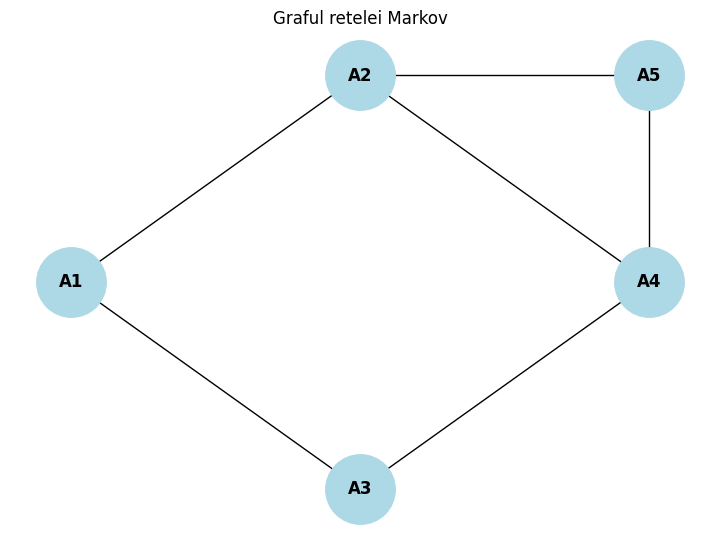

In [2]:
# ============================================
# SUBPUNCTUL A
# Construirea grafului si determinarea clicilor
# ============================================

import pyagrum as gum
import networkx as nx
import matplotlib.pyplot as plt

from IPython.display import display


# --------------------------------------------
# 1. Definim variabilele si muchiile
# --------------------------------------------

variabile = ["A1", "A2", "A3", "A4", "A5"]

muchii = [
    ("A1", "A2"),
    ("A1", "A3"),
    ("A2", "A4"),
    ("A2", "A5"),
    ("A3", "A4"),
    ("A4", "A5")
]


# --------------------------------------------
# 2. Construim graful cu networkx
# --------------------------------------------

# nx.Graph() creeaza un graf neorientat
graf = nx.Graph()

# Adaugam cele 5 noduri
graf.add_nodes_from(variabile)

# Adaugam muchiile
graf.add_edges_from(muchii)


# --------------------------------------------
# 3. Determinam clicile maximale
# --------------------------------------------

# find_cliques gaseste clicile maximale
clici_maximale = list(nx.find_cliques(graf))

# Sortam fiecare clica pentru o afisare mai clara
clici_maximale = [
    sorted(clica)
    for clica in clici_maximale
]

# Sortam si lista de clici
clici_maximale = sorted(clici_maximale)

print("Clicile maximale sunt:")

for index, clica in enumerate(clici_maximale, start=1):
    print(f"Clica {index}: {clica}")


# --------------------------------------------
# 4. Construim structura retelei in pyAgrum
# --------------------------------------------

# Cream o retea Markov
retea = gum.MarkovRandomField()

# Adaugam cele 5 variabile.
# Fiecare variabila are 2 valori posibile: 0 si 1.
for variabila in variabile:
    retea.add(variabila, 2)

# Adaugam un factor pentru fiecare clica maximala.
# Aici construim structura grafului.
# Potentialele numerice sunt calculate la punctul b).
for clica in clici_maximale:
    retea.addFactor(clica)

print("\nGraful afisat cu pyAgrum:")

display(retea)


# --------------------------------------------
# 5. Afisam si salvam graful cu networkx
# --------------------------------------------

# Stabilim pozitiile nodurilor
pozitii = {
    "A1": (0, 1),
    "A2": (1, 2),
    "A3": (1, 0),
    "A4": (2, 1),
    "A5": (2, 2)
}

plt.figure(figsize=(7, 5))

nx.draw(
    graf,
    pos=pozitii,
    with_labels=True,
    node_color="lightblue",
    node_size=2500,
    font_size=12,
    font_weight="bold",
    edge_color="black"
)

plt.title("Graful retelei Markov")

# Salvam graful pe disc
plt.savefig("graf_retea_markov.png", bbox_inches="tight")

plt.show()

In [4]:
# ============================================
# SUBPUNCTUL B
# Probabilitatea comuna si configuratiile MAP
# ============================================

import math
import itertools


# --------------------------------------------
# 1. Definim variabilele si clicile maximale
# --------------------------------------------

variabile = ["A1", "A2", "A3", "A4", "A5"]

clici_maximale = [
    ["A1", "A2"],
    ["A1", "A3"],
    ["A3", "A4"],
    ["A2", "A4", "A5"]
]


# Enuntul nu precizeaza beta.
# Alegem beta = 1 ca exemplu.
beta = 1.0


# --------------------------------------------
# 2. Functia care calculeaza potentialul unei clici
# --------------------------------------------

def calculeaza_potential(clica, configuratie, beta):
    """
    Calculeaza potentialul unei clici:

        potential = exp(beta * suma(ai * aj))

    configuratie este un dictionar de forma:
        {"A1": 1, "A2": 0, ...}
    """

    suma_perechi = 0

    # Parcurgem toate perechile distincte de variabile din clica
    for var1, var2 in itertools.combinations(clica, 2):

        # Adunam produsul valorilor celor doua variabile
        suma_perechi += (
            configuratie[var1] * configuratie[var2]
        )

    # Aplicam formula din enunt
    potential = math.exp(beta * suma_perechi)

    return potential


# --------------------------------------------
# 3. Generam toate configuratiile posibile
# --------------------------------------------

# Fiecare din cele 5 variabile poate fi 0 sau 1.
# Deci avem 2^5 = 32 de configuratii.
configuratii = list(
    itertools.product([0, 1], repeat=5)
)

print("Numarul de configuratii:", len(configuratii))


# --------------------------------------------
# 4. Calculam ponderea fiecarei configuratii
# --------------------------------------------

ponderi = []

for valori in configuratii:

    # Transformam tuplul intr-un dictionar.
    #
    # Exemplu:
    # (1, 0, 1, 0, 1) devine
    # {"A1": 1, "A2": 0, "A3": 1, "A4": 0, "A5": 1}
    configuratie = dict(zip(variabile, valori))

    # Vom inmulti potentialele, asa ca pornim de la 1
    pondere = 1.0

    # Calculam si inmultim potentialele tuturor clicilor
    for clica in clici_maximale:

        potential = calculeaza_potential(
            clica,
            configuratie,
            beta
        )

        pondere *= potential

    # Salvam ponderea configuratiei
    ponderi.append(pondere)


# --------------------------------------------
# 5. Calculam constanta de normalizare Z
# --------------------------------------------

# Z este suma ponderilor tuturor configuratiilor
Z = sum(ponderi)

print("Valoarea lui beta:", beta)
print("Constanta Z:", Z)


# --------------------------------------------
# 6. Calculam probabilitatile
# --------------------------------------------

probabilitati = []

for pondere in ponderi:

    # P(configuratie) = pondere / Z
    probabilitate = pondere / Z

    probabilitati.append(probabilitate)


# --------------------------------------------
# 7. Afisam probabilitatea fiecarei configuratii
# --------------------------------------------

print("\nProbabilitatile tuturor configuratiilor:\n")

for configuratie, probabilitate in zip(
    configuratii,
    probabilitati
):
    print(
        configuratie,
        "->",
        round(probabilitate, 6)
    )


# Verificam daca probabilitatile insumeaza 1
print("\nSuma probabilitatilor:", sum(probabilitati))


# --------------------------------------------
# 8. Determinam configuratiile MAP
# --------------------------------------------

# Gasim cea mai mare probabilitate
probabilitate_maxima = max(probabilitati)

print("\nProbabilitatea maxima:", probabilitate_maxima)

print("Configuratiile MAP sunt:")

for configuratie, probabilitate in zip(
    configuratii,
    probabilitati
):

    # isclose compara numere reale si permite mici erori de calcul
    if math.isclose(
        probabilitate,
        probabilitate_maxima,
        rel_tol=1e-12
    ):
        print(configuratie)

Numarul de configuratii: 32
Valoarea lui beta: 1.0
Constanta Z: 706.2787274114461

Probabilitatile tuturor configuratiilor:

(0, 0, 0, 0, 0) -> 0.001416
(0, 0, 0, 0, 1) -> 0.001416
(0, 0, 0, 1, 0) -> 0.001416
(0, 0, 0, 1, 1) -> 0.003849
(0, 0, 1, 0, 0) -> 0.001416
(0, 0, 1, 0, 1) -> 0.001416
(0, 0, 1, 1, 0) -> 0.003849
(0, 0, 1, 1, 1) -> 0.010462
(0, 1, 0, 0, 0) -> 0.001416
(0, 1, 0, 0, 1) -> 0.003849
(0, 1, 0, 1, 0) -> 0.003849
(0, 1, 0, 1, 1) -> 0.028439
(0, 1, 1, 0, 0) -> 0.001416
(0, 1, 1, 0, 1) -> 0.003849
(0, 1, 1, 1, 0) -> 0.010462
(0, 1, 1, 1, 1) -> 0.077304
(1, 0, 0, 0, 0) -> 0.001416
(1, 0, 0, 0, 1) -> 0.001416
(1, 0, 0, 1, 0) -> 0.001416
(1, 0, 0, 1, 1) -> 0.003849
(1, 0, 1, 0, 0) -> 0.003849
(1, 0, 1, 0, 1) -> 0.003849
(1, 0, 1, 1, 0) -> 0.010462
(1, 0, 1, 1, 1) -> 0.028439
(1, 1, 0, 0, 0) -> 0.003849
(1, 1, 0, 0, 1) -> 0.010462
(1, 1, 0, 1, 0) -> 0.010462
(1, 1, 0, 1, 1) -> 0.077304
(1, 1, 1, 0, 0) -> 0.010462
(1, 1, 1, 0, 1) -> 0.028439
(1, 1, 1, 1, 0) -> 0.077304
(1, 1, 

In [3]:
# ============================================
# SUBPUNCTUL C
# Model Ising: favorizam vecinii egali
# ============================================

import math
import itertools

import pyagrum as gum

from IPython.display import display


# --------------------------------------------
# 1. Definim variabilele si muchiile
# --------------------------------------------

variabile = ["A1", "A2", "A3", "A4", "A5"]

muchii = [
    ("A1", "A2"),
    ("A1", "A3"),
    ("A2", "A4"),
    ("A2", "A5"),
    ("A3", "A4"),
    ("A4", "A5")
]


# J > 0 inseamna ca favorizam vecinii cu valori egale
J = 1.0


# --------------------------------------------
# 2. Construim reteaua Ising in pyAgrum
# --------------------------------------------

retea_ising = gum.MarkovRandomField()

# Adaugam variabilele binare
for variabila in variabile:
    retea_ising.add(variabila, 2)


# Adaugam cate un factor pentru fiecare muchie
for var1, var2 in muchii:

    # Factorul depinde de cele doua variabile vecine
    factor = retea_ising.addFactor([var1, var2])

    # Parcurgem toate combinatiile posibile pentru doi vecini
    #
    # (0, 0)
    # (0, 1)
    # (1, 0)
    # (1, 1)
    for valoare1, valoare2 in itertools.product(
        [0, 1],
        repeat=2
    ):

        # Daca valorile sunt egale, indicatorul este 1.
        # Altfel, indicatorul este 0.
        indicator_egalitate = int(valoare1 == valoare2)

        # Potentialul:
        #
        # exp(J), daca valorile sunt egale
        # 1, daca valorile sunt diferite
        potential = math.exp(J * indicator_egalitate)

        # Adaugam valoarea in factorul retelei
        factor[
            {
                var1: valoare1,
                var2: valoare2
            }
        ] = potential


print("Reteaua Ising:")

display(retea_ising)


# --------------------------------------------
# 3. Generam toate configuratiile
# --------------------------------------------

configuratii = list(
    itertools.product([0, 1], repeat=5)
)


# --------------------------------------------
# 4. Calculam ponderea fiecarei configuratii
# --------------------------------------------

ponderi = []

for valori in configuratii:

    # Asociem fiecare variabila cu valoarea ei
    configuratie = dict(zip(variabile, valori))

    # Pornim de la 1 pentru ca inmultim potentialele
    pondere = 1.0

    # Pentru fiecare muchie calculam potentialul
    for var1, var2 in muchii:

        # Verificam daca vecinii au valori egale
        indicator_egalitate = int(
            configuratie[var1] == configuratie[var2]
        )

        # Calculam potentialul muchiei
        potential = math.exp(J * indicator_egalitate)

        # Inmultim cu ponderile celorlalte muchii
        pondere *= potential

    ponderi.append(pondere)


# --------------------------------------------
# 5. Calculam probabilitatile
# --------------------------------------------

Z = sum(ponderi)

probabilitati = [
    pondere / Z
    for pondere in ponderi
]

print("\nConstanta de normalizare Z:", Z)
print("Suma probabilitatilor:", sum(probabilitati))


# --------------------------------------------
# 6. Determinam configuratiile MAP
# --------------------------------------------

probabilitate_maxima = max(probabilitati)

print("\nProbabilitatea maxima:", probabilitate_maxima)
print("Configuratiile MAP sunt:")

for configuratie, probabilitate in zip(
    configuratii,
    probabilitati
):

    if math.isclose(
        probabilitate,
        probabilitate_maxima,
        rel_tol=1e-12
    ):
        print(configuratie)

Reteaua Ising:


(pyagrum.MarkovRandomField@0xcb3edc0) MRF{nodes: 5, edges: 6, domainSize: 32, dim: 24}


Constanta de normalizare Z: 1539.8766942362959
Suma probabilitatilor: 0.9999999999999999

Probabilitatea maxima: 0.26198772603206133
Configuratiile MAP sunt:
(0, 0, 0, 0, 0)
(1, 1, 1, 1, 1)
